# Locked-rotor current-loop analysis

Analyze the closed-loop transfer from the q-axis current reference to measured, unfiltered q-axis current. The pybind11 wrapper runs the C++ drive and scheduler at the configured operating point and identifies a discrete small-signal model from the selected input and output.

Select the project's Python environment as the notebook kernel. If the extension is missing, run these commands from the repository root with that environment active.

```sh
uv pip install pybind11
PYTHON="$(command -v python)" pmsmcpp/scripts/build_python.sh
```

In [1]:
from pathlib import Path
import sys

root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "pmsmcpp" / "MODULE.bazel").is_file()),
    None,
)
if root is None:
    raise FileNotFoundError("Start the notebook kernel inside the MotorSim repository.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

import control as ct
import matplotlib.pyplot as plt
import numpy as np

from motorsim.models.drive import DriveModel

config = root / "pmsmcpp/configs/simplefoc_locked_rotor_config.json"
drive = DriveModel(config)

print("Writable input ports:", drive.input_ports)
print("Available output ports:", drive.output_ports)

Writable input ports: ('load.value', 'current_reference.value')
Available output ports: ('current_feedback.id', 'current_feedback.iq', 'current_pi.id_filtered', 'current_pi.id_ref', 'current_pi.iq_applied', 'current_pi.iq_filtered', 'current_pi.vd', 'current_pi.vq', 'current_reference.value', 'inverter.va', 'inverter.vb', 'inverter.vc', 'load.value', 'pmsm.ia', 'pmsm.ib', 'pmsm.ic', 'pmsm.omega', 'pmsm.theta', 'svpwm.duty_a', 'svpwm.duty_b', 'svpwm.duty_c')


## Operating point and sampled model

The supplied configuration requests 2 A with the rotor locked. Select the reference source and current feedback port from the discovered names. The perturbation is in amperes.

In [2]:
input_port = "current_reference.value"
output_port = "current_feedback.iq"
delta_a = 1e-3

system, point = drive.linearize(input_port, output_port, delta=delta_a)
nyquist_hz = 0.5 / system.dt

print(f"Reference: {point['input_value']:.6g} A")
print(f"Measured current: {point['output_value']:.6g} A")
print(f"Sample time: {system.dt * 1e6:.3g} µs")
print(f"Nyquist frequency: {nyquist_hz:g} Hz")
print(f"DC gain: {float(system.dcgain()):.6g} A/A")
system

Reference: 2 A
Measured current: 2 A
Sample time: 50 µs
Nyquist frequency: 10000 Hz
DC gain: 1 A/A


<LinearIOSystem:sys[2]:['current_reference.value']->['current_feedback.iq']>

## Pole locations

Poles strictly inside the unit circle indicate stability of the modes visible from this reference to this measurement. The identified model describes the local input/output channel around the selected operating point.

Poles: [0.86297169+0.j 0.9270336 +0.j 0.97044098+0.j]
Largest pole magnitude: 0.970441


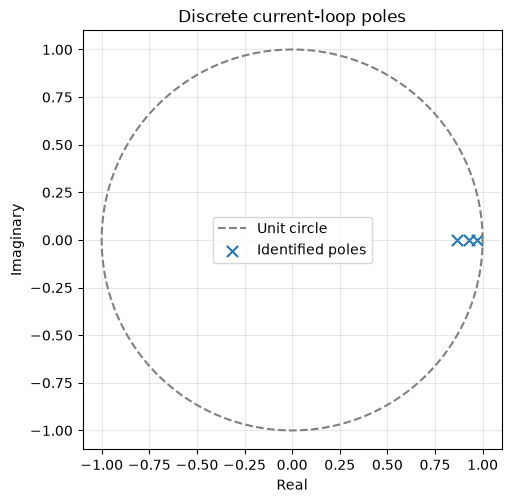

In [3]:
poles = system.pole()
largest_radius = np.max(np.abs(poles))
print("Poles:", poles)
print(f"Largest pole magnitude: {largest_radius:.6f}")

angle = np.linspace(0, 2 * np.pi, 361)
fig, ax = plt.subplots(figsize=(5, 5), layout="constrained")
ax.plot(np.cos(angle), np.sin(angle), "--", color="0.5", label="Unit circle")
ax.scatter(poles.real, poles.imag, marker="x", s=65, label="Identified poles")
ax.set(xlabel="Real", ylabel="Imaginary", title="Discrete current-loop poles")
ax.set_aspect("equal")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

## Frequency response

Plot the response to a small sinusoidal current-reference perturbation. The frequency axis ends below Nyquist. Compare with a model identified at half the perturbation amplitude to check sensitivity to the identification step size.

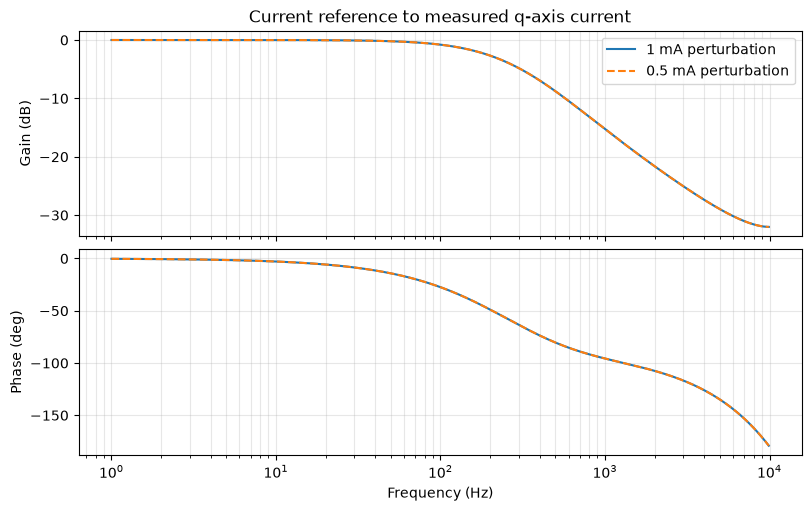

Change in largest pole magnitude at half the perturbation: 7.41e-08


In [4]:
half_step_system, _ = drive.linearize(input_port, output_port, delta=delta_a / 2)
frequency_hz = np.geomspace(1, 0.99 * nyquist_hz, 400)
omega = 2 * np.pi * frequency_hz

fig, (gain_ax, phase_ax) = plt.subplots(
    2, 1, sharex=True, figsize=(8, 5), layout="constrained"
)
for model, amplitude, style in (
    (system, delta_a, "-"),
    (half_step_system, delta_a / 2, "--"),
):
    magnitude, phase, _ = ct.frequency_response(model, omega)
    gain_ax.semilogx(
        frequency_hz, 20 * np.log10(magnitude), style,
        label=f"{amplitude * 1e3:g} mA perturbation",
    )
    phase_ax.semilogx(frequency_hz, np.rad2deg(np.unwrap(phase)), style)

gain_ax.set(ylabel="Gain (dB)", title="Current reference to measured q-axis current")
phase_ax.set(xlabel="Frequency (Hz)", ylabel="Phase (deg)")
for ax in (gain_ax, phase_ax):
    ax.grid(which="both", alpha=0.3)
gain_ax.legend()
plt.show()

print(
    f"Change in largest pole magnitude at half the perturbation: "
    f"{abs(largest_radius - np.max(np.abs(half_step_system.pole()))):.2e}"
)